# Predictive Modeling: How Accurately Can We Predict a Person's Claim?

Step 5 of the project (see `docs/methodology.md`).

The business question: a health insurer needs to forecast what its members' claims will cost, to budget for future claims, set its overall premium level, and decide where prevention programs would help most. Under the US Affordable Care Act, individual premiums cannot depend on health status, so the forecast supports planning rather than pricing each person.

Notebook 03 explained which factors are associated with claims. This notebook asks a different question: how close are the predictions for people the model has never seen? Success here is measured by MAE (mean absolute error): how far off the predictions are, on average, in dollars.

The notebook follows the order of the work:

1. Prepare the inputs, split the data, and set a baseline
2. Compare four models with cross-validation
3. Choose a final model, then test it once on held-out data
4. Error analysis: who does the model get wrong?
5. What drives the predictions?
6. Fairness: does the model need gender and region?
7. What this means for the insurer

Claim units are undocumented; amounts are treated as dollars. The data may be synthetic, so results describe this dataset.

In [1]:
import os
from pathlib import Path

import duckdb
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import mean_absolute_error
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.inspection import permutation_importance

# Run from the project root so the database path and the src folder work
if Path.cwd().name == "notebooks":
    os.chdir("..")

# Our own code: builds the model inputs (src/models/features.py)
from src.models.features import build_features

# Load the cleaned table (1,332 rows) and close the connection
con = duckdb.connect("data/processed/insurance.duckdb", read_only=True)
df = con.sql("SELECT * FROM insurance_cleaned").df()
con.close()

# Group labels, used later to check errors by group
df["group"] = (df["smoker"].map({True: "Smoker", False: "Non-smoker"})
               + ", BMI " + (df["bmi"] >= 30).map({True: "30+", False: "<30"}))

sns.set_theme(style="whitegrid")
df.shape

(1332, 11)

## 1. Inputs, train-test split and baseline

scikit-learn needs every input as a number. `build_features` turns yes/no columns into 1/0, turns gender and region into 0/1 columns, and adds the BMI 30+ and smoker × BMI 30+ columns from notebook 03. These steps look at one row at a time, so they are safe before splitting.

In [2]:
# X = the 12 inputs, y = claim (what we want to predict)
X, y = build_features(df)
X.head()

,age,bmi,bloodpressure,diabetic,children,smoker,bmi_30_plus,smoker_bmi_30,gender_male,region_northwest,region_southeast,region_southwest
0,39.0,23.2,91,1,0,0,0,0,1,0,1,0
1,24.0,30.1,87,0,0,0,1,0,1,0,1,0
2,19.0,41.1,100,0,0,0,1,0,1,1,0,0
3,20.0,43.0,86,0,0,0,1,0,1,1,0,0
4,30.0,53.1,97,0,0,0,1,0,1,1,0,0


In [3]:
# Train-test split: 80% training, 20% test
# Rows are shuffled first (the file is sorted by claim), and random_state fixes the shuffle
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(X_train.shape, X_test.shape)

(1065, 12) (267, 12)


In [4]:
# Baseline 1: predict the training mean for everyone
mean_pred = [y_train.mean()] * len(y_train)
mae_mean = mean_absolute_error(y_train, mean_pred)

# Baseline 2: predict the training median for everyone
median_pred = [y_train.median()] * len(y_train)
mae_median = mean_absolute_error(y_train, median_pred)

print(f"Training mean: {y_train.mean():,.0f}, training median: {y_train.median():,.0f}")
print(f"Baseline MAE (mean):   {mae_mean:,.0f}")
print(f"Baseline MAE (median): {mae_median:,.0f}")

Training mean: 13,338, training median: 9,386
Baseline MAE (mean):   9,148
Baseline MAE (median): 8,394


The data was split into 80% training (1,065 people) and 20% test (267 people). The test set is set aside until the final evaluation.

Before any modeling, a baseline sets the bar every model has to beat: predicting the same claim for everyone.

| Baseline | Prediction for everyone | MAE |
|---|---|---|
| Training mean | 13,338 | 9,148 |
| Training median | 9,386 | 8,394 |

The median baseline has the lower error. Claims are right-skewed, so the mean is pulled up by a few large claims, and the median is the single value that minimizes absolute error. The baseline to beat is an MAE of 8,394: guessing the median is off by about 8,394 per person on average.

## 2. Comparing models with cross-validation

Cross-validation splits the training data into 5 parts. Each model trains on 4 parts and is scored on the 5th, five times over, so every part gets a turn. The average score shows how well a model does on data it did not train on, without touching the test set.

### Linear regression

Same inputs as Model 2 in notebook 03.

In [5]:
# 5-fold cross-validation of a linear regression on the training data
# scikit-learn reports errors as negative numbers, so the minus sign flips them back
lin_folds = -cross_val_score(LinearRegression(), X_train, y_train, cv=5, scoring="neg_mean_absolute_error")
mae_linear = lin_folds.mean()

print(f"Linear regression, cross-validated MAE: {mae_linear:,.0f}")
print("MAE in each fold:", lin_folds.round(0))
print(f"Lower than the baseline by: {(1 - mae_linear / mae_median) * 100:.0f}%")

Linear regression, cross-validated MAE: 4,136
MAE in each fold: [4099. 4433. 3864. 4431. 3850.]
Lower than the baseline by: 51%


The linear regression's predictions are off by about 4,136 per person on average, roughly half the baseline's error (51% lower). Across the five folds, the MAE ranged from about 3,850 to 4,430, so differences of a few hundred dollars between models may not be meaningful.

### Ridge and Lasso

Ridge and Lasso add a penalty that shrinks the coefficients, which helps when a model overfits. The inputs are scaled first so the penalty treats them fairly. Putting the scaling inside a pipeline means it is learned from the training folds only.

In [6]:
# Pipeline: scale the inputs, then fit the model (both learned from the training folds only)
ridge = make_pipeline(StandardScaler(), Ridge(alpha=1.0))
mae_ridge = -cross_val_score(ridge, X_train, y_train, cv=5, scoring="neg_mean_absolute_error").mean()
print(f"Ridge, cross-validated MAE: {mae_ridge:,.0f}")

lasso = make_pipeline(StandardScaler(), Lasso(alpha=1.0))
mae_lasso = -cross_val_score(lasso, X_train, y_train, cv=5, scoring="neg_mean_absolute_error").mean()
print(f"Lasso, cross-validated MAE: {mae_lasso:,.0f}")

Ridge, cross-validated MAE: 4,136
Lasso, cross-validated MAE: 4,136


Both give the same MAE as linear regression (4,136). The linear model is not overfitting: with 12 inputs and 1,065 training rows, there is enough data for every coefficient. Regularization adds nothing here, so plain linear regression stays as the linear model.

### Random forest

Many decision trees, each asking yes/no questions (smoker? BMI over 30?), averaged together. Trees do not need scaling.

In [7]:
# Random forest; random_state fixes its randomness
forest = RandomForestRegressor(random_state=42)
forest_folds = -cross_val_score(forest, X_train, y_train, cv=5, scoring="neg_mean_absolute_error")
mae_forest = forest_folds.mean()
print(f"Random forest, cross-validated MAE: {mae_forest:,.0f}")
print(f"Difference from linear regression: {mae_linear - mae_forest:,.0f}")

# Overfitting check: the forest's error on the same data it trained on
forest.fit(X_train, y_train)
mae_forest_train = mean_absolute_error(y_train, forest.predict(X_train))
print(f"Random forest, error on its own training data: {mae_forest_train:,.0f}")

Random forest, cross-validated MAE: 4,100
Difference from linear regression: 36
Random forest, error on its own training data: 1,534


In [8]:
# Remove the two BMI 30+ columns: can each model find the smoking x BMI pattern on its own?
X_train_plain = X_train.drop(columns=["bmi_30_plus", "smoker_bmi_30"])

mae_lin_plain = -cross_val_score(LinearRegression(), X_train_plain, y_train, cv=5, scoring="neg_mean_absolute_error").mean()
mae_forest_plain = -cross_val_score(RandomForestRegressor(random_state=42), X_train_plain, y_train, cv=5, scoring="neg_mean_absolute_error").mean()

print(f"Without the BMI 30+ columns: linear {mae_lin_plain:,.0f}, random forest {mae_forest_plain:,.0f}")
print(f"Extra error for linear regression without them: {mae_lin_plain - mae_linear:,.0f}")

Without the BMI 30+ columns: linear 4,980, random forest 4,088
Extra error for linear regression without them: 844


The random forest's MAE is 4,100, only 36 less than linear regression. That is far smaller than the variation between folds (about 600), so the two perform about the same.

On its own training data, the forest's error is only about 1,534. It largely memorizes the data it trains on. Judged on training data alone, it would have looked more than twice as accurate as it really is, which is why models are judged with cross-validation.

| Model | With BMI 30+ columns | Without them |
|---|---|---|
| Linear regression | 4,136 | 4,980 |
| Random forest | 4,100 | 4,088 |

The forest finds the smoking × BMI pattern on its own. Linear regression needs it built in, and without it the error rises by about 840. The interaction found in notebook 03 is what lets the simpler, explainable model keep up with the forest.

### Gradient boosting

Trees built one after another, each one correcting the mistakes of the ones before.

In [9]:
# Gradient boosting; random_state fixes its randomness
boosting = GradientBoostingRegressor(random_state=42)
boosting_folds = -cross_val_score(boosting, X_train, y_train, cv=5, scoring="neg_mean_absolute_error")
mae_boosting = boosting_folds.mean()
print(f"Gradient boosting, cross-validated MAE: {mae_boosting:,.0f}")

# Every model used the same 5 folds, so they can be compared fold by fold
print("Linear:        ", lin_folds.round(0))
print("Random forest: ", forest_folds.round(0))
print("Boosting:      ", boosting_folds.round(0))
print("Boosting minus linear:", (boosting_folds - lin_folds).round(0))   # negative = boosting has less error

print(f"Average gain over linear: {mae_linear - mae_boosting:,.0f} ({(1 - mae_boosting / mae_linear) * 100:.0f}%)")

Gradient boosting, cross-validated MAE: 3,967
Linear:         [4099. 4433. 3864. 4431. 3850.]
Random forest:  [4127. 4248. 3717. 4482. 3925.]
Boosting:       [4044. 3939. 3710. 4320. 3824.]
Boosting minus linear: [ -56. -494. -155. -111.  -26.]
Average gain over linear: 168 (4%)


| Model | Cross-validated MAE |
|---|---|
| Baseline (median) | 8,394 |
| Linear regression | 4,136 |
| Ridge / Lasso | 4,136 |
| Random forest | 4,100 |
| Gradient boosting | 3,967 |

Gradient boosting has the lowest error. Its gain over linear regression is modest (about 168 per person, or 4%), but it beats both linear regression and the random forest in every one of the five folds, so the gain is consistent rather than luck.

## 3. Model choice and final test

Decision, made before looking at the test set: gradient boosting is the final predictive model. Linear regression stays as the explainable model from notebook 03. It is slightly less accurate, but every effect can be read in dollars, which matters when forecasts have to be explained to managers or regulators.

The test set is used once, now.

In [10]:
# Final evaluation on the test set: the only time the test set is used

# Gradient boosting (final model): train on all training data, then predict the test set
boosting.fit(X_train, y_train)
mae_boosting_test = mean_absolute_error(y_test, boosting.predict(X_test))

# Linear regression for reference
lin_reg = LinearRegression()
lin_reg.fit(X_train, y_train)
mae_lin_test = mean_absolute_error(y_test, lin_reg.predict(X_test))

# Baseline: guess the TRAINING median for every test person, then score that guess
baseline_pred = [y_train.median()] * len(y_test)
mae_baseline_test = mean_absolute_error(y_test, baseline_pred)

print(f"Gradient boosting, test MAE:          {mae_boosting_test:,.0f}")
print(f"Linear regression, test MAE:          {mae_lin_test:,.0f}")
print(f"Baseline (training median), test MAE: {mae_baseline_test:,.0f}")
print(f"Boosting vs baseline: {(1 - mae_boosting_test / mae_baseline_test) * 100:.0f}% lower error")
print(f"Boosting vs linear: {mae_lin_test - mae_boosting_test:,.0f} lower ({(1 - mae_boosting_test / mae_lin_test) * 100:.0f}%)")

Gradient boosting, test MAE:          3,697
Linear regression, test MAE:          4,083
Baseline (training median), test MAE: 8,183
Boosting vs baseline: 55% lower error
Boosting vs linear: 386 lower (9%)


| Model | Cross-validated MAE | Test MAE |
|---|---|---|
| Baseline (training median) | 8,394 | 8,183 |
| Linear regression | 4,136 | 4,083 |
| Gradient boosting | 3,967 | 3,697 |

Gradient boosting is the best model in both cross-validation and the test set. Its predictions are off by about 3,700 per person on average, compared with about 8,200 for the median baseline: 55% lower error. For the insurer, that is a much closer estimate of each member's expected claim cost than a flat average.

The test results are close to the cross-validation estimates and rank the models in the same order, so cross-validation gave a reliable picture.

Against linear regression the gain is modest: about 170 per person in cross-validation and about 390 on the test set (4% to 9%). The test set is a single sample of 267 people, so the cross-validation figure is the steadier estimate.

## 4. Error analysis: who does the model get wrong?

An average error can hide groups the model gets badly wrong. Error = actual minus predicted, so a positive value means the model predicted too low (the member's cost would be under-forecast).

In [11]:
# Error for each test person (positive = predicted too low)
test_errors = y_test - boosting.predict(X_test)

# Put the errors next to each person's group (X_test keeps the original row numbers)
errors = pd.DataFrame({
    "group": df.loc[X_test.index, "group"],
    "error": test_errors,
    "abs_error": test_errors.abs(),
})

# MAE (size of the misses) and mean error (direction of the misses) in each group
errors.groupby("group").agg(n=("error", "size"), mae=("abs_error", "mean"), mean_error=("error", "mean")).round(0)

,n,mae,mean_error
group,,,
"Non-smoker, BMI 30+",111,3796.0,125.0
"Non-smoker, BMI <30",104,3440.0,-246.0
"Smoker, BMI 30+",29,4610.0,-379.0
"Smoker, BMI <30",23,3233.0,711.0


In [12]:
# How many test people does the model miss by more than 10,000, and are they smokers?
big_miss = test_errors.abs() > 10000
print("Errors above 10,000:", big_miss.sum())
print(df.loc[X_test.index[big_miss], "smoker"].value_counts())
print("Of those, predicted too low:", (test_errors[big_miss] > 0).sum())

Errors above 10,000: 12
smoker
False    9
True     3
Name: count, dtype: int64
Of those, predicted too low: 11


| Group | n | MAE | Mean error |
|---|---|---|---|
| Non-smokers, BMI 30+ | 111 | 3,796 | +125 |
| Non-smokers, BMI under 30 | 104 | 3,440 | -246 |
| Smokers, BMI 30+ | 29 | 4,610 | -379 |
| Smokers, BMI under 30 | 23 | 3,233 | +711 |

- MAE shows how big the misses are; mean error shows whether they lean one way. A mean error near zero means balanced, not accurate.
- Obese smokers have the largest typical error (4,610), and non-obese smokers the smallest (3,233).
- No group is badly biased. The mean errors are a few hundred dollars on small groups, compared with the 6,500 to 7,400 bias Model 1 had in notebook 03.
- 12 test people have errors above 10,000. 9 of them are non-smokers, and 11 were predicted too low. These are the high-claim non-smokers seen in EDA and notebook 03, and no variable in the data explains them.

For the insurer: a small group of non-smokers with unusually high claims is under-forecast by more than 10,000, so plans that rely on the forecast would fall short for them. Predicting them would need information this dataset does not have, such as medical history.

## 5. What drives the predictions?

Gradient boosting has no coefficients to read. Permutation importance shuffles one input at a time on the test set and measures how much the MAE gets worse. A bigger increase means the model relies more on that input.

                  increase_in_mae  plus_minus
smoker_bmi_30              3154.0       201.0
smoker                     2218.0       186.0
bloodpressure              1329.0       149.0
bmi                         271.0        58.0
region_southeast            155.0        18.0
region_northwest            110.0        27.0
age                          58.0        38.0
region_southwest             45.0        21.0
gender_male                   7.0         4.0
children                     -0.0        48.0
diabetic                     -1.0        12.0
bmi_30_plus                  -4.0         2.0


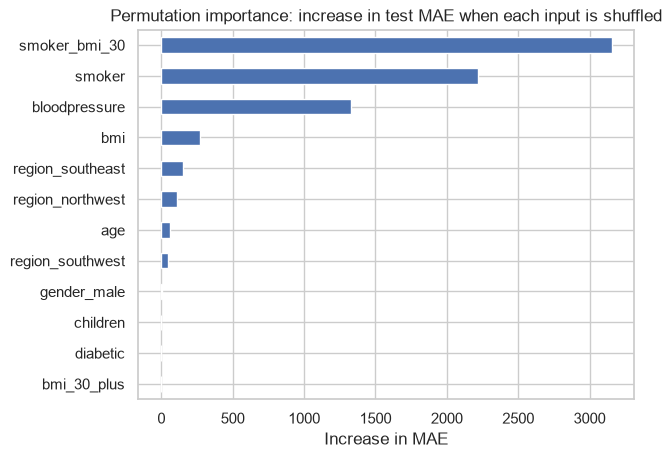

In [13]:
# Shuffle each input 10 times and measure how much the test MAE gets worse
result = permutation_importance(boosting, X_test, y_test, n_repeats=10,
                                random_state=42, scoring="neg_mean_absolute_error")

# Average increase in error per input (bigger = more important), and how much it varies between shuffles
importance = pd.DataFrame({
    "increase_in_mae": result.importances_mean,
    "plus_minus": result.importances_std,
}, index=X_test.columns).sort_values("increase_in_mae", ascending=False)
print(importance.round(0))

importance["increase_in_mae"].sort_values().plot(kind="barh")
plt.title("Permutation importance: increase in test MAE when each input is shuffled")
plt.xlabel("Increase in MAE")
plt.show()

| Input | Increase in test MAE when shuffled |
|---|---|
| Smoker × BMI 30+ | 3,154 |
| Smoker | 2,218 |
| Blood pressure | 1,329 |
| BMI | 271 |
| Region | 45 to 155 |
| Age | 58 |
| Gender, children, diabetic, BMI 30+ | about 0 |

The ranking matches notebook 03: obese smoking, smoking and blood pressure matter most, while age, gender and diabetic status contribute little. Two different methods, a regression on all the data and a predictive model tested on new people, point to the same factors.

One difference: children was significant in notebook 03 (about +694 per child) but adds almost nothing here. An effect can be real and still too small, next to an average error of about 3,700, to noticeably improve predictions on 267 test people.

Permutation importance shows what the model relies on, not how large an effect is or whether it causes higher claims.

## 6. Fairness: does the model need gender and region?

Under the US Affordable Care Act, individual health premiums may vary by age, tobacco use, location and family size, but not by gender or health status. Gradient boosting was cross-validated without gender and region to see what each contributes.

In [14]:
region_cols = ["region_northwest", "region_southeast", "region_southwest"]

# 1. Without gender
no_gender = -cross_val_score(GradientBoostingRegressor(random_state=42),
                             X_train.drop(columns=["gender_male"]), y_train, cv=5, scoring="neg_mean_absolute_error")

# 2. Without region
no_region = -cross_val_score(GradientBoostingRegressor(random_state=42),
                             X_train.drop(columns=region_cols), y_train, cv=5, scoring="neg_mean_absolute_error")

# 3. Without gender and region
no_both = -cross_val_score(GradientBoostingRegressor(random_state=42),
                           X_train.drop(columns=["gender_male"] + region_cols), y_train, cv=5, scoring="neg_mean_absolute_error")

# Change in error compared with all inputs (positive = more error without the variable)
print(f"All inputs:                {mae_boosting:,.0f}")
print(f"Without gender:            {no_gender.mean():,.0f}   change per fold: {(no_gender - boosting_folds).round(0)}")
print(f"Without region:            {no_region.mean():,.0f}   change per fold: {(no_region - boosting_folds).round(0)}")
print(f"Without gender and region: {no_both.mean():,.0f}   change per fold: {(no_both - boosting_folds).round(0)}")

All inputs:                3,967
Without gender:            3,974   change per fold: [-37.  50. -30.  30.  20.]
Without region:            4,071   change per fold: [ 53. 160. 146. 130.  33.]
Without gender and region: 4,042   change per fold: [  3. 147.  96.  88.  37.]


| Inputs | Cross-validated MAE | Change |
|---|---|---|
| All inputs | 3,967 | |
| Without gender | 3,974 | +7 |
| Without region | 4,071 | +104 |
| Without gender and region | 4,042 | +74 |

- Gender adds nothing: removing it changes the error by 7, with folds going both ways. It can be left out with no loss of accuracy.
- Region adds a small but consistent amount: removing it raises the error by about 100 per person, in every fold. Location is a permitted pricing factor, so keeping it is defensible.
- BMI and blood pressure, two of the strongest inputs, are health status, which the ACA does not allow in individual-market premiums. As built, the model could not set premiums in that market. It fits settings where health information can legally be used, or internal uses such as forecasting claim costs.

## 7. What this means for the insurer

Written after the analysis was finished.

- Accuracy: the final model (gradient boosting) forecasts a member's claim cost to within about 3,700 on average, 55% less error than a flat estimate (about 8,200).
- Simple vs complex: an explainable linear regression, using the smoking × BMI interaction found in notebook 03, comes within about 4% to 9% of the best model. If forecasts must be explained line by line, it is a strong alternative at a small cost in accuracy.
- What drives claims: obese smoking, smoking and blood pressure dominate, in line with notebook 03.
- Where it fails: a small group of non-smokers with unusually high claims is underestimated by more than 10,000. Better data, not a better algorithm, is the fix.
- Fairness: gender can be dropped at no cost. Because of the health variables, the model supports budgeting and prevention planning rather than individual premiums in the ACA individual market.

Not done here: hyperparameter tuning and partial dependence plots. The default models already beat the baseline by a wide margin, and permutation importance plus the BMI 30+ columns already show how the model uses smoking and BMI.

## Export for the Tableau dashboard

The forecast-accuracy panel in the dashboard uses the test-set errors above. They are saved to a small file so the dashboard's numbers come from this notebook rather than being typed in by hand.

In [15]:
# Small results table for the Tableau dashboard (forecast accuracy panel)
# Test-set MAE: how far off each approach is, on average, for members it never saw
model_results = pd.DataFrame({
    "approach": ["Flat estimate (same for everyone)", "Linear regression", "Gradient boosting"],
    "avg_error_per_member": [mae_baseline_test, mae_lin_test, mae_boosting_test],
})

model_results.to_csv("data/processed/tableau_model_results.csv", index=False)
model_results.round(0)

,approach,avg_error_per_member
0,Flat estimate (same for everyone),8183.0
1,Linear regression,4083.0
2,Gradient boosting,3697.0
